# Group Project Implementation Assignment
# Module 6 — Model Development, Optimization and Evaluation
## Title: Real-Time Network Intrusion Detection Using Machine Learning-Based Multi-Class Classification
**Group 19 | Cybersecurity and Network Security**

The members are
1. Adugna Necho Mulatu
2.	Aminadab Tewhibo Mihret
3.	Hussen Yasin Mohammed
4.	Abdulfetah Hayerdin Mohammed
5.	Nebiyu Mesfin Fikade
### Evaluation
- Five target classes: **Normal, DoS, Probe, U2R, R2L**.
- `KDDTest+` remains untouched until final evaluation.
- Stratified training/validation split is created from `KDDTrain+`.
- Preprocessing is kept inside reproducible pipelines.
- **SMOTENC** is used only inside the training/cross-validation workflow to prevent leakage.
- Model evaluation reports Accuracy, Macro Precision, Macro Recall, Macro F1, per-class metrics, FPR, confusion matrix, and inference latency.
- **GridSearchCV** with Macro F1 is used for Random Forest optimization.
- XGBoost uses `multi:softprob` for probability/confidence output.
- The complete preprocessing + model pipeline is saved for dashboard/API integration.
- The result is a **near-real-time proof-of-concept**, not a production enterprise IDS.


## 1. Install and import required libraries

Before building or training ML models, we need to gather all necessary external packages and python tools.

*   `pip install`: Quietly installs packages like `kagglehub` (to retrieve the dataset), `imbalanced-learn` (for handling class imbalances), `xgboost`, and `joblib` (for saving the model).
*   `import statements`: Loads data manipulation libraries (`pandas`, `numpy`), visualization frameworks (`matplotlib`, `seaborn`), standard modeling/splitting algorithms from scikit-learn, specialized pipelines from imblearn, and the xgboost classifier. It also defines a static random seed (42) to guarantee reproducible outputs.

In [ ]:
!pip -q install kagglehub imbalanced-learn xgboost joblib


In [ ]:
import os, json, time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 2. Load NSL-KDD


Acquiring the raw experimental network traffic data from a hosted public repository.
*   Utilizes `kagglehub` to download the standard NSL-KDD data directly.
*   Since raw text files (`KDDTrain+.txt` and `KDDTest+.txt`) lack a header, this cell explicitly defines a 43-column schema (`column_names`) and loads them into Pandas DataFrames, ensuring that the critical target label is bound to the column name `class` and validation difficulty levels are retained.

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("hassan06/nslkdd")
print("Dataset path:", dataset_path)

column_names = [
    "duration","protocol_type","service","flag","src_bytes","dst_bytes",
    "land","wrong_fragment","urgent","hot","num_failed_logins","logged_in",
    "num_compromised","root_shell","su_attempted","num_root",
    "num_file_creations","num_shells","num_access_files","num_outbound_cmds",
    "is_host_login","is_guest_login","count","srv_count","serror_rate",
    "srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
    "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
    "dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate",
    "dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate",
    "dst_host_srv_rerror_rate","class","difficulty_level"
]

df_train = pd.read_csv(os.path.join(dataset_path, "KDDTrain+.txt"), names=column_names)
df_test = pd.read_csv(os.path.join(dataset_path, "KDDTest+.txt"), names=column_names)

print("KDDTrain+:", df_train.shape)
print("KDDTest+ :", df_test.shape)


Using Colab cache for faster access to the 'nslkdd' dataset.
Dataset path: /kaggle/input/nslkdd
KDDTrain+: (125973, 43)
KDDTest+ : (22544, 43)


## 3. Initial exploration

Inspecting data health (checking for missing data points and discovering target labels).
*   `display(df_train.head())`: Previews the first 5 records of the dataset.
*   `df_train.isnull().sum()`: Checks and aggregates missing values across each column, verifying that the dataset is cleanly populated.
*   `df_train["class"].value_counts()`: Performs a frequency count on the raw target class column to understand how many categorical attack types exist (like neptune, satan, normal).

In [ ]:
display(df_train.head())
print("\nMissing values:")
display(df_train.isnull().sum().sort_values(ascending=False).head(10))
print("\nRaw training labels:")
display(df_train["class"].value_counts().sort_index())


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class,difficulty_level
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21



Missing values:


,0
duration,0
protocol_type,0
service,0
flag,0
src_bytes,0
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0



Raw training labels:


,count
class,
back,956
buffer_overflow,30
ftp_write,8
guess_passwd,53
imap,11
ipsweep,3599
land,18
loadmodule,9
multihop,7


## 4. Five-class target mapping


The proposal defines five classes. Raw NSL-KDD labels are explicitly grouped before training. Mapping more than 30 raw, granular network attack types into 5 standardized target categories (Normal, DoS, Probe, U2R, R2L) required for standard multi-class intrusion detection.
*   Defines a python dictionary `attack_mapping` matching granular labels (e.g., `smurf` -> `DoS`, `buffer_overflow` -> `U2R`) and checks if any classes in either split went unmapped.
*   Translates target string classes (Normal, DoS, etc.) into integer identifiers (0 to 4) stored as `target_id`.
*   Plots a bar chart showing the severe target imbalance, highlighting the extreme rarity of certain categories like U2R.

In [ ]:
attack_mapping = {
    "normal": "Normal",

    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS",
    "smurf": "DoS", "teardrop": "DoS", "apache2": "DoS",
    "udpstorm": "DoS", "processtable": "DoS", "mailbomb": "DoS",
    "worm": "DoS",

    "ipsweep": "Probe", "nmap": "Probe", "satan": "Probe",
    "portsweep": "Probe", "mscan": "Probe", "saint": "Probe",
    "snmpguess": "Probe",

    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L",
    "multihop": "R2L", "phf": "R2L", "spy": "R2L",
    "warezclient": "R2L", "warezmaster": "R2L",
    "snmpgetattack": "R2L", "named": "R2L", "sendmail": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "httptunnel": "R2L",

    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R",
    "rootkit": "U2R", "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R"
}

df_train["target"] = df_train["class"].map(attack_mapping)
df_test["target"] = df_test["class"].map(attack_mapping)

unmapped_train = sorted(df_train.loc[df_train["target"].isna(), "class"].unique())
unmapped_test = sorted(df_test.loc[df_test["target"].isna(), "class"].unique())
print("Unmapped training labels:", unmapped_train)
print("Unmapped test labels:", unmapped_test)

if unmapped_train or unmapped_test:
    raise ValueError("All raw labels must be mapped before training.")

class_names = ["Normal", "DoS", "Probe", "U2R", "R2L"]
label_to_id = {v:i for i,v in enumerate(class_names)}
id_to_label = {i:v for v,i in label_to_id.items()}

df_train["target_id"] = df_train["target"].map(label_to_id)
df_test["target_id"] = df_test["target"].map(label_to_id)

display(df_train["target"].value_counts().reindex(class_names))

Unmapped training labels: []
Unmapped test labels: []


,count
target,
Normal,67343
DoS,45927
Probe,11656
U2R,52
R2L,995


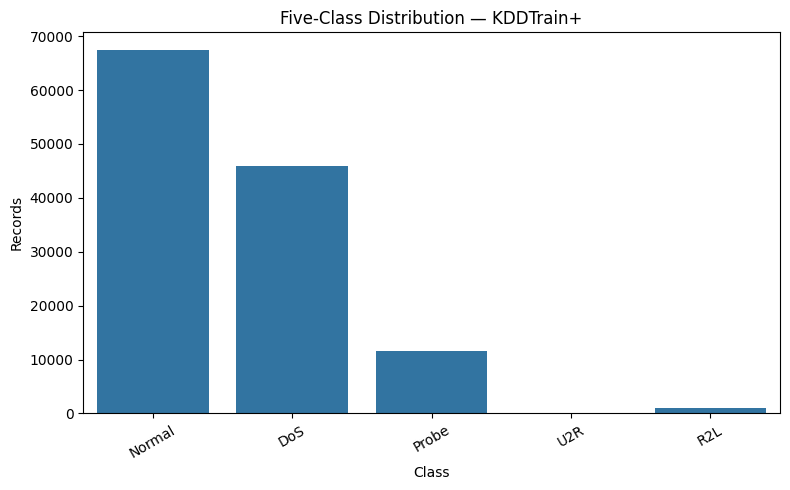

In [ ]:
counts = df_train["target"].value_counts().reindex(class_names)
plt.figure(figsize=(8,5))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Five-Class Distribution — KDDTrain+")
plt.xlabel("Class")
plt.ylabel("Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 5. Feature/target separation and stratified validation split

Splitting features from target outputs and making sure our training/validation partition possesses the exact same ratios of classes.
*   Drops auxiliary and meta-data columns (`class`, `target`, `target_id`, `difficulty_level`) from the feature space.
*   Categorizes variables into discrete lists (`categorical_features` and `numerical_features`).
*   Performs a stratified split (`train_test_split`) using a 17.65% validation ratio on the training data. This cleanly separates a distinct validation subset without ever touching the true, pristine `KDDTest+` test set.

In [ ]:
drop_columns = ["class", "target", "target_id", "difficulty_level"]

X_full = df_train.drop(columns=drop_columns)
y_full = df_train["target_id"].astype(int)
X_test = df_test.drop(columns=drop_columns)
y_test = df_test["target_id"].astype(int)

categorical_features = ["protocol_type", "service", "flag"]
numerical_features = [c for c in X_full.columns if c not in categorical_features]

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full,
    test_size=0.1765,
    stratify=y_full,
    random_state=RANDOM_STATE
)

print("Training :", X_train.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)
print("KDDTest+ is reserved for final evaluation only.")


Training : (103738, 41)
Validation: (22235, 41)
Final test: (22544, 41)
KDDTest+ is reserved for final evaluation only.


## 6. Preprocessing pipeline

Creating an automated preprocessing mechanism so raw strings and continuous numbers are appropriately scaled and encoded.

*   Sets up a `ColumnTransformer`. For numerical features, it applies a median imputer and scales values via `StandardScaler` (giving them 0 mean and unit variance).
*   For categorical columns, it replaces missing inputs with the most frequent value and translates string categories into one-hot binary matrices (`OneHotEncoder`).

In [ ]:
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", one_hot)
    ]), categorical_features)
])


## 7. Evaluation functions

Constructing reusable helper functions to easily calculate performance metrics.
*   `evaluate_model`: Takes a model, generates predictions, computes macro performance metrics (Accuracy, Macro Precision, Macro Recall, Macro F1), prints a classification report, and plots a confusion matrix heat map.
*   `multiclass_fpr`: Extracts True Negatives, False Positives, False Negatives, and True Positives from the confusion matrix to calculate the False Positive Rate (FPR) specifically for each of the 5 categories.

In [ ]:
def evaluate_model(model, X_eval, y_eval, model_name):
    pred = model.predict(X_eval)
    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Macro Precision": precision_score(y_eval, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_eval, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_eval, pred, average="macro", zero_division=0)
    }
    print(f"\n===== {model_name} =====")
    print(classification_report(
        y_eval, pred, labels=range(5), target_names=class_names, zero_division=0
    ))
    cm = confusion_matrix(y_eval, pred, labels=range(5))
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()
    return result, pred

def multiclass_fpr(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=range(5))
    total = cm.sum()
    rows = []
    for i, name in enumerate(class_names):
        tp = cm[i,i]
        fn = cm[i,:].sum() - tp
        fp = cm[:,i].sum() - tp
        tn = total - tp - fn - fp
        rows.append({
            "Class": name,
            "False Positive Rate": fp/(fp+tn) if (fp+tn) else 0.0
        })
    return pd.DataFrame(rows)


## 8. Decision Tree baseline

Creating a basic baseline using a simple Decision Tree structure.
*   Builds a scikit-learn pipeline chaining our preprocessing steps with a `DecisionTreeClassifier`.
*   Uses `class_weight="balanced"` to penalize minority-class prediction errors more severely during training to combat class imbalance. It fits the model and outputs validation metrics.


===== Decision Tree Baseline =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     11887
         DoS       1.00      1.00      1.00      8106
       Probe       1.00      1.00      1.00      2057
         U2R       0.78      0.78      0.78         9
         R2L       0.95      0.97      0.96       176

    accuracy                           1.00     22235
   macro avg       0.94      0.95      0.95     22235
weighted avg       1.00      1.00      1.00     22235



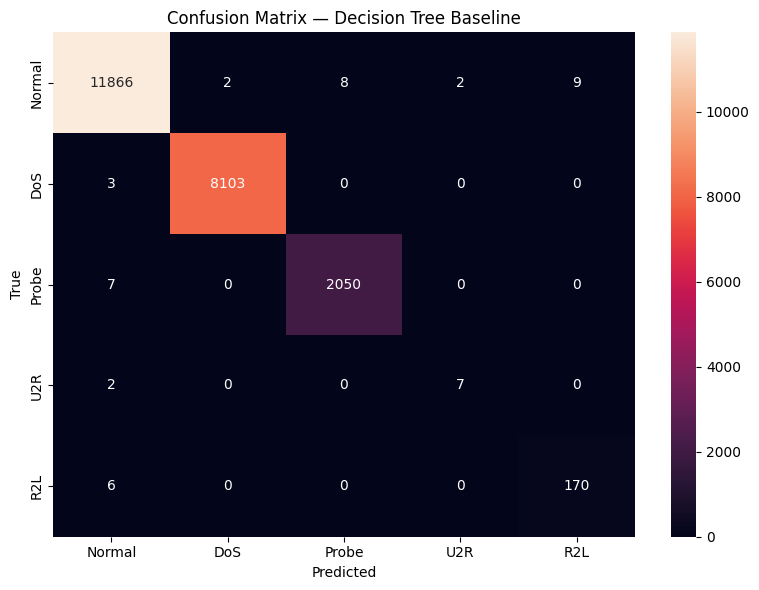

In [ ]:
dt_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
])
dt_pipeline.fit(X_train, y_train)
dt_result, dt_pred = evaluate_model(dt_pipeline, X_val, y_val, "Decision Tree Baseline")


## 9. Random Forest baseline

Training an ensemble of decision trees to increase generalization.
*   Instantiates a pipeline matching our preprocessor with a `RandomForestClassifier` running 200 trees in parallel.
*   Fits the ensemble and runs the evaluation utilities on the validation set to compare with the basic Decision Tree.


===== Random Forest Baseline =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     11887
         DoS       1.00      1.00      1.00      8106
       Probe       1.00      1.00      1.00      2057
         U2R       0.71      0.56      0.62         9
         R2L       1.00      0.95      0.98       176

    accuracy                           1.00     22235
   macro avg       0.94      0.90      0.92     22235
weighted avg       1.00      1.00      1.00     22235



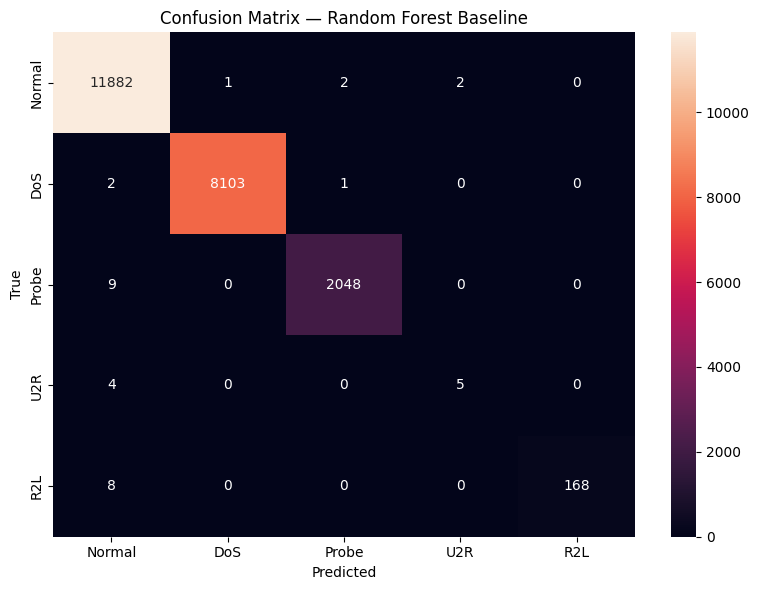

In [ ]:
rf_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced"
    ))
])
rf_pipeline.fit(X_train, y_train)
rf_result, rf_pred = evaluate_model(rf_pipeline, X_val, y_val, "Random Forest Baseline")


## 10. XGBoost comparative model

Training a gradient boosting model as an alternative baseline framework.
*   Initializes a multiclass gradient booster (`XGBClassifier`) optimized using the multi-class logarithmic loss objective function (`multi:softprob`).
*   Fits the model on training data and computes validation metrics.


===== XGBoost =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     11887
         DoS       1.00      1.00      1.00      8106
       Probe       1.00      1.00      1.00      2057
         U2R       0.80      0.89      0.84         9
         R2L       0.98      0.99      0.99       176

    accuracy                           1.00     22235
   macro avg       0.96      0.98      0.97     22235
weighted avg       1.00      1.00      1.00     22235



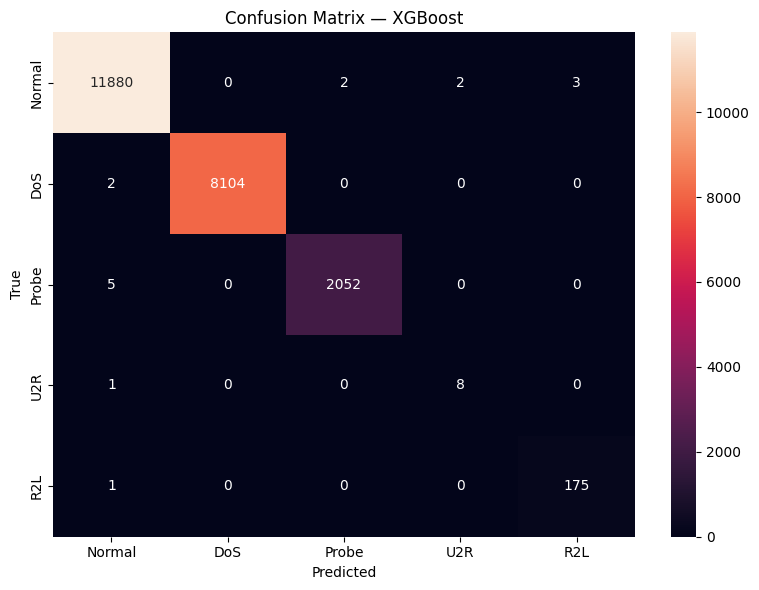

In [ ]:
xgb_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=5,
        eval_metric="mlogloss",
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
xgb_pipeline.fit(X_train, y_train)
xgb_result, xgb_pred = evaluate_model(xgb_pipeline, X_val, y_val, "XGBoost")


## 11. Validation model comparison

Consolidating performance results across all baselines.
*   Gathers validation metrics dictionaries for our Decision Tree, Random Forest, and XGBoost baselines into a single structured Pandas DataFrame.
*   Sorts this table by the balanced Macro F1 score to reveal which algorithm is fundamentally most capable of handling imbalanced network anomaly signatures.

In [ ]:
comparison_df = pd.DataFrame([dt_result, rf_result, xgb_result])
display(comparison_df.sort_values("Macro F1", ascending=False))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
2,XGBoost,0.999280,0.956283,0.975988,0.965661
0,Decision Tree Baseline,0.998246,0.944370,0.947629,0.945986
1,Random Forest Baseline,0.998696,0.942154,0.900987,0.919480


## 12. Leakage-safe SMOTENC

SMOTENC is applied to the original mixed-type feature table and is placed inside the imbalanced-learn pipeline. This prevents oversampling before cross-validation and avoids the fractional one-hot problem of ordinary SMOTE after one-hot encoding. Balancing our dataset by synthesizing minority examples safely, preventing data leakage.

*   Uses imbalanced-learn's Pipeline to chain a `SMOTENC` oversampler directly with our preprocessing and random forest classifier.
*   Because `SMOTENC` is wrapped inside the pipeline, oversampling only happens on the active training folds during training—preventing synthetic information from leaking into the validation split.


===== Random Forest + SMOTENC =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     11887
         DoS       1.00      1.00      1.00      8106
       Probe       1.00      1.00      1.00      2057
         U2R       0.82      1.00      0.90         9
         R2L       0.98      0.98      0.98       176

    accuracy                           1.00     22235
   macro avg       0.96      1.00      0.98     22235
weighted avg       1.00      1.00      1.00     22235



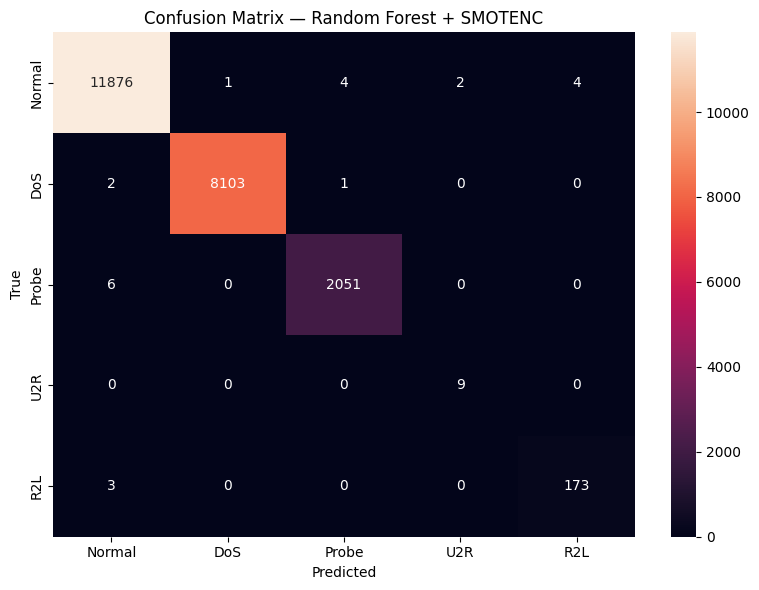

,Class,False Positive Rate
0,Normal,0.001063
1,DoS,0.000071
2,Probe,0.000248
3,U2R,0.000090
4,R2L,0.000181


In [ ]:
categorical_indices = [X_train.columns.get_loc(c) for c in categorical_features]

leakage_safe_rf = ImbPipeline([
    ("smotenc", SMOTENC(
        categorical_features=categorical_indices,
        random_state=RANDOM_STATE,
        k_neighbors=1
    )),
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE, n_jobs=-1, class_weight=None
    ))
])

leakage_safe_rf.fit(X_train, y_train)
smote_result, smote_pred = evaluate_model(
    leakage_safe_rf, X_val, y_val, "Random Forest + SMOTENC"
)
display(multiclass_fpr(y_val, smote_pred))


## 13. GridSearchCV with Macro F1

Finding the absolute best hyperparameter combinations via systematic cross-validation.

*   Defines a parameter grid (testing variations of tree count, depth, and split criteria) and sets up 3-fold stratified cross-validation.
*   Executes a grid search across the pipeline using Macro F1 as the evaluation metric to find the optimal configuration (`best_rf`).

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 20],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    leakage_safe_rf,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV Macro F1:", round(grid_search.best_score_, 4))
best_rf = grid_search.best_estimator_


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 250}
Best CV Macro F1: 0.9019


## 14. Optimized validation evaluation

Testing our final tuned SMOTENC-backed pipeline on the validation data.

*   Validates the best estimator found during the grid search on the validation split, displaying the final validation confusion matrix, metrics table, and multi-class False Positive Rates.


===== Optimized Random Forest + SMOTENC =====
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     11887
         DoS       1.00      1.00      1.00      8106
       Probe       1.00      1.00      1.00      2057
         U2R       0.90      1.00      0.95         9
         R2L       0.96      0.98      0.97       176

    accuracy                           1.00     22235
   macro avg       0.97      0.99      0.98     22235
weighted avg       1.00      1.00      1.00     22235



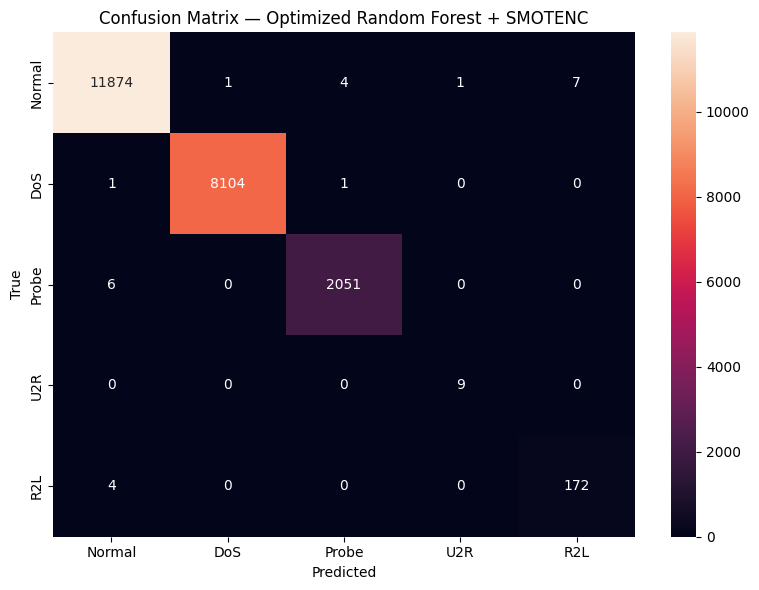

,Class,False Positive Rate
0,Normal,0.001063
1,DoS,0.000071
2,Probe,0.000248
3,U2R,0.000045
4,R2L,0.000317


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Optimized Random Forest + SMOTENC,0.998876,0.971483,0.994603,0.982503


In [ ]:
best_val_result, best_val_pred = evaluate_model(
    best_rf, X_val, y_val, "Optimized Random Forest + SMOTENC"
)
val_fpr = multiclass_fpr(y_val, best_val_pred)
display(val_fpr)
display(pd.DataFrame([best_val_result]))


## 15. Final evaluation on untouched KDDTest+

The independent `KDDTest+` benchmark split is evaluated after model selection. It is not live network traffic and does not establish current production performance. The official test set remains outside fitting and hyperparameter selection.



===== Optimized Random Forest + SMOTENC — Final Test =====
              precision    recall  f1-score   support

      Normal       0.64      0.97      0.77      9711
         DoS       0.96      0.77      0.85      7460
       Probe       0.86      0.54      0.67      2752
         U2R       0.58      0.10      0.18        67
         R2L       0.95      0.06      0.11      2554

    accuracy                           0.75     22544
   macro avg       0.80      0.49      0.52     22544
weighted avg       0.81      0.75      0.71     22544



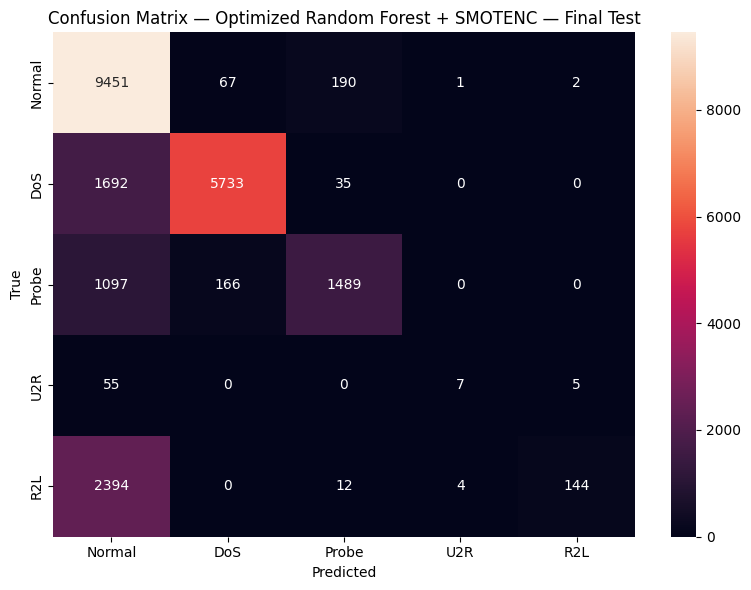

,Class,False Positive Rate
0,Normal,0.408166
1,DoS,0.015447
2,Probe,0.011975
3,U2R,0.000222
4,R2L,0.000350


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Optimized Random Forest + SMOTENC — Final Test,0.746274,0.800803,0.488729,0.51548


In [ ]:
final_result, final_pred = evaluate_model(
    best_rf, X_test, y_test, "Optimized Random Forest + SMOTENC — Final Test"
)
final_fpr = multiclass_fpr(y_test, final_pred)
display(final_fpr)
display(pd.DataFrame([final_result]))


## 16. Success criteria check

Comparing our model's actual test results with our stated project targets.

*   Creates a tabular summary displaying project threshold rules (e.g., Accuracy >= 90%, Macro F1 >= 0.85, Class FPR < 5%) side-by-side with our model's actual performance metrics on the final test split, marking each as Pass or Fail.

In [ ]:
max_fpr = final_fpr["False Positive Rate"].max()
criteria = pd.DataFrame({
    "Criterion": [
        "Accuracy >= 90%",
        "Macro F1 >= 0.85",
        "Macro Precision >= 0.85",
        "Macro Recall >= 0.85",
        "Maximum class FPR < 5%"
    ],
    "Measured": [
        final_result["Accuracy"],
        final_result["Macro F1"],
        final_result["Macro Precision"],
        final_result["Macro Recall"],
        max_fpr
    ],
    "Pass": [
        final_result["Accuracy"] >= .90,
        final_result["Macro F1"] >= .85,
        final_result["Macro Precision"] >= .85,
        final_result["Macro Recall"] >= .85,
        max_fpr < .05
    ]
})
display(criteria)


,Criterion,Measured,Pass
0,Accuracy >= 90%,0.746274,False
1,Macro F1 >= 0.85,0.515480,False
2,Macro Precision >= 0.85,0.800803,False
3,Macro Recall >= 0.85,0.488729,False
4,Maximum class FPR < 5%,0.408166,False


## 17. Error analysis

Analyzing precisely where the model's predictions went wrong.

*   Parses the final test confusion matrix to extract and list specific true-versus-predicted class mismatches (e.g., how often actual R2L attacks were misclassified as Normal), sorted by frequency to prioritize model refinement.

In [ ]:
cm = confusion_matrix(y_test, final_pred, labels=range(5))
errors = []
for true_id in range(5):
    for pred_id in range(5):
        if true_id != pred_id and cm[true_id, pred_id] > 0:
            errors.append({
                "True Class": id_to_label[true_id],
                "Predicted Class": id_to_label[pred_id],
                "Count": int(cm[true_id, pred_id])
            })
error_df = pd.DataFrame(errors).sort_values("Count", ascending=False)
display(error_df.head(15))


,True Class,Predicted Class,Count
10,R2L,Normal,2394
4,DoS,Normal,1692
6,Probe,Normal,1097
1,Normal,Probe,190
7,Probe,DoS,166
0,Normal,DoS,67
8,U2R,Normal,55
5,DoS,Probe,35
11,R2L,Probe,12
9,U2R,R2L,5


## 18. Confidence scores and threat severity

Adding interpretability and actionability to prediction outputs.

*   Uses `predict_proba` to fetch the maximum prediction probability confidence score for incoming records.
*   Maps the predicted class category to a threat classification tier (Low, Medium, High, Critical) so network security response teams can easily prioritize alerts.

In [ ]:
severity_map = {
    "Normal": "Low",
    "Probe": "Medium",
    "DoS": "High",
    "R2L": "High",
    "U2R": "Critical"
}

probabilities = best_rf.predict_proba(X_test.head(5))
predictions = best_rf.predict(X_test.head(5))

confidence_df = pd.DataFrame({
    "Predicted Class": [id_to_label[int(i)] for i in predictions],
    "Confidence": probabilities.max(axis=1)
})
confidence_df["Threat Severity"] = confidence_df["Predicted Class"].map(severity_map)
display(confidence_df)


,Predicted Class,Confidence,Threat Severity
0,DoS,0.999992,High
1,DoS,0.998410,High
2,Normal,0.957789,Low
3,Probe,0.933661,Medium
4,Normal,0.517605,Low


## 19. Inference latency

This cell measures batch inference time on the notebook's Colab runtime. The result is environment-specific and should not be treated as a deployment service-level objective or proof that the system captures live packets in real time.


In [ ]:
sample_size = min(1000, len(X_test))
latency_input = X_test.iloc[:sample_size]

start = time.perf_counter()
_ = best_rf.predict(latency_input)
elapsed = time.perf_counter() - start
avg_ms = (elapsed / sample_size) * 1000

print("Records:", sample_size)
print(f"Total time: {elapsed:.4f} seconds")
print(f"Average end-to-end inference: {avg_ms:.4f} ms/record")
print("Target <100 ms:", avg_ms < 100)


Records: 1000
Total time: 0.1190 seconds
Average end-to-end inference: 0.1190 ms/record
Target <100 ms: True


## 20. Feature importance

Inspecting which features most heavily drive model decisions.

*   Accesses the inner `RandomForestClassifier` estimator inside the pipeline.
*   Extracts feature importances, maps them to their respective preprocessed column names (including those generated during one-hot encoding), and sorts them in descending order to identify key network metrics.

In [ ]:
rf_model = best_rf.named_steps["model"]
fitted_preprocessor = best_rf.named_steps["preprocess"]
feature_names = fitted_preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance_df.head(20))


,Feature,Importance
1,num__src_bytes,0.083419
29,num__dst_host_srv_count,0.075329
2,num__dst_bytes,0.066858
8,num__logged_in,0.039323
31,num__dst_host_diff_srv_rate,0.038105
20,num__srv_count,0.037364
32,num__dst_host_same_src_port_rate,0.037147
34,num__dst_host_serror_rate,0.032722
19,num__count,0.031685
101,cat__service_telnet,0.029147


## 21. Save the complete preprocessing + model pipeline

Exporting the complete preprocessing + model pipeline for prototype inference. The saved artifact is version-sensitive and should only be loaded from a trusted source. It is not, by itself, a deployed or production-ready security system.


In [ ]:
from pathlib import Path
import hashlib
import json
import joblib

artifact_dir = Path("artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)
model_path = artifact_dir / "group19_final_nids_random_forest_pipeline.joblib"
mapping_path = artifact_dir / "group19_nids_class_mapping.json"
evaluation_path = artifact_dir / "evaluation.json"
checksum_path = artifact_dir / "model.sha256"

# Save the entire preprocessing + SMOTENC + Random Forest pipeline.
joblib.dump(best_rf, model_path, compress=3)

mapping = {
    "class_names": class_names,
    "label_to_id": label_to_id,
    "id_to_label": {str(k): v for k, v in id_to_label.items()},
    "feature_columns": list(X_train.columns),
    "threat_severity": severity_map,
}
mapping_path.write_text(json.dumps(mapping, indent=2), encoding="utf-8")

# Record measured results from the current notebook runtime; no fallback metrics.
evaluation = {
    "project": "Group 19 NSL-KDD multi-class NIDS",
    "dataset": "NSL-KDD KDDTrain+ / KDDTest+",
    "training_records": int(len(X_train)),
    "validation_records": int(len(X_val)),
    "official_test_records": int(len(X_test)),
    "features": int(len(X_train.columns)),
    "classes": class_names,
    "random_state": RANDOM_STATE,
    "best_parameters": grid_search.best_params_,
    "best_cv_macro_f1": float(grid_search.best_score_),
    "validation_metrics": {k: float(v) for k, v in best_val_result.items() if k != "Model"},
    "official_test_metrics": {k: float(v) for k, v in final_result.items() if k != "Model"},
    "official_test_class_recall": {
        name: float(classification_report(
            y_test, final_pred, labels=range(5), target_names=class_names,
            output_dict=True, zero_division=0
        )[name]["recall"]) for name in class_names
    },
    "official_test_false_positive_rate_ovr": {
        row["Class"]: float(row["False Positive Rate"])
        for _, row in final_fpr.iterrows()
    },
    "disclosure": "KDDTest+ is a benchmark split, not live network traffic. SMOTENC synthesizes training examples only.",
}
evaluation_path.write_text(json.dumps(evaluation, indent=2), encoding="utf-8")

digest = hashlib.sha256(model_path.read_bytes()).hexdigest()
checksum_path.write_text(f"{digest}  {model_path.name}\n", encoding="utf-8")

print("Model artifact:", model_path)
print("Class mapping:", mapping_path)
print("Measured evaluation:", evaluation_path)
print("SHA-256:", digest)

# Package the exported artifacts. In Colab, this triggers a browser download.
import zipfile
artifact_zip = Path("group19_nids_model_artifacts.zip")
with zipfile.ZipFile(artifact_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for artifact_file in artifact_dir.iterdir():
        if artifact_file.is_file():
            zf.write(artifact_file, arcname=artifact_file.name)
print("Artifact bundle:", artifact_zip)
try:
    from google.colab import files as colab_files
    colab_files.download(str(artifact_zip))
except ImportError:
    print("Not running in Colab; retrieve the ZIP from the current working directory.")


## 22. Reload verification

Testing the exported pipeline file to ensure it matches memory states.

*   Loads the model pipeline file back into memory (`reloaded_model`) and generates predictions on 20 test records.
*   Compares these outputs with predictions from the active memory model to guarantee serialization preserved pipeline integrity.

In [ ]:
reloaded_model = joblib.load("group19_final_nids_random_forest_pipeline.joblib")
print(
    "Reloaded predictions match:",
    np.array_equal(
        reloaded_model.predict(X_test.head(20)),
        best_rf.predict(X_test.head(20))
    )
)


Reloaded predictions match: True


## 23. Learning curve: training versus validation Macro F1

This diagnostic compares training and cross-validation Macro F1 as the amount of training data increases. Because the estimator includes SMOTENC inside its pipeline, resampling is fitted only within each training fold. This cell may take time to run.

**Important:** the official KDDTest+ set is not used for this learning curve.


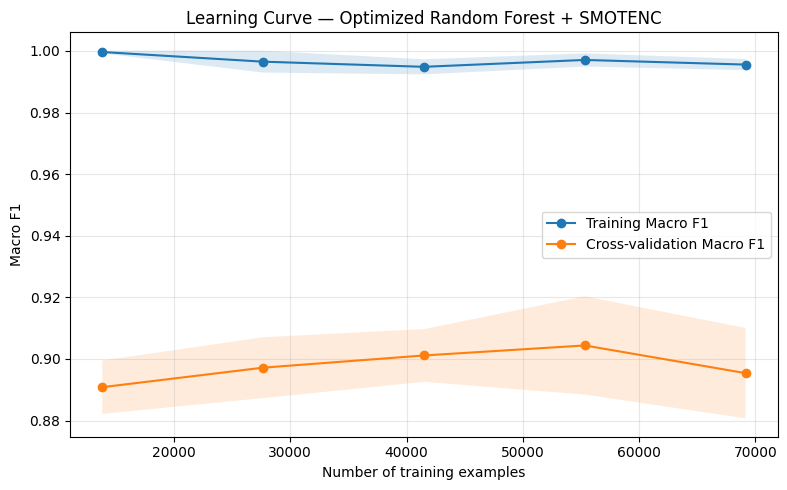

,Training examples,Mean training Macro F1,Mean CV Macro F1,CV standard deviation
0,13831,0.9996,0.8908,0.0086
1,27663,0.9965,0.8972,0.0099
2,41494,0.9948,0.9011,0.0086
3,55326,0.9971,0.9044,0.0159
4,69158,0.9956,0.8954,0.0147


In [ ]:
from sklearn.model_selection import learning_curve

learning_sizes = np.linspace(0.2, 1.0, 5)
lc_sizes, lc_train_scores, lc_val_scores = learning_curve(
    estimator=best_rf,
    X=X_train,
    y=y_train,
    train_sizes=learning_sizes,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE
)

lc_train_mean = lc_train_scores.mean(axis=1)
lc_train_std = lc_train_scores.std(axis=1)
lc_val_mean = lc_val_scores.mean(axis=1)
lc_val_std = lc_val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(lc_sizes, lc_train_mean, marker="o", label="Training Macro F1")
plt.plot(lc_sizes, lc_val_mean, marker="o", label="Cross-validation Macro F1")
plt.fill_between(lc_sizes, lc_train_mean-lc_train_std, lc_train_mean+lc_train_std, alpha=0.15)
plt.fill_between(lc_sizes, lc_val_mean-lc_val_std, lc_val_mean+lc_val_std, alpha=0.15)
plt.xlabel("Number of training examples")
plt.ylabel("Macro F1")
plt.title("Learning Curve — Optimized Random Forest + SMOTENC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

learning_curve_summary = pd.DataFrame({
    "Training examples": lc_sizes,
    "Mean training Macro F1": lc_train_mean,
    "Mean CV Macro F1": lc_val_mean,
    "CV standard deviation": lc_val_std
})
display(learning_curve_summary.round(4))


## 24. One-versus-rest ROC curves on the official test set

This cell reports ROC curves and AUC for each of the five classes using the model's predicted probabilities. The test set is used here for final reporting only; do not use these results to tune hyperparameters.


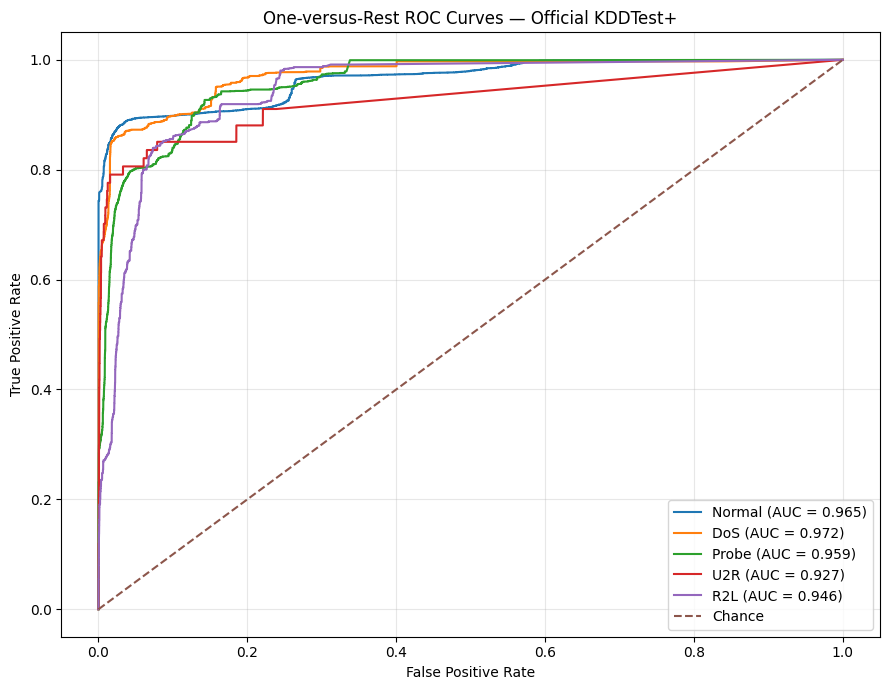

,Class,One-vs-rest ROC AUC
0,Normal,0.9650
1,DoS,0.9723
2,Probe,0.9589
3,U2R,0.9267
4,R2L,0.9457


In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

test_probabilities = best_rf.predict_proba(X_test)
y_test_binary = label_binarize(y_test, classes=list(range(len(class_names))))

plt.figure(figsize=(9, 7))
roc_auc_by_class = {}
for class_index, class_name in enumerate(class_names):
    fpr_curve, tpr_curve, _ = roc_curve(
        y_test_binary[:, class_index],
        test_probabilities[:, class_index]
    )
    class_auc = auc(fpr_curve, tpr_curve)
    roc_auc_by_class[class_name] = class_auc
    plt.plot(fpr_curve, tpr_curve, label=f"{class_name} (AUC = {class_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-versus-Rest ROC Curves — Official KDDTest+")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Class": list(roc_auc_by_class.keys()),
    "One-vs-rest ROC AUC": list(roc_auc_by_class.values())
}).round(4))


## 25. Written error analysis and limitations

The recorded official KDDTest+ results indicate a generalization gap between validation and independent test performance. The final test accuracy is approximately 74.63%, Macro F1 is 0.5155, Macro recall is 0.4887, and the maximum one-versus-rest class false-positive rate is approximately 40.82% (Normal class). These results do not meet the proposal's current performance targets.

The class-wise report shows particularly weak recall for R2L (0.06) and U2R (0.10), while Normal recall is high (0.97). This means many R2L and U2R examples are missed, and a substantial number of non-Normal records are incorrectly classified as Normal. Possible explanations to investigate include severe class imbalance, limited examples of rare attack types in training, differences between training and test attack distributions, and overlap in feature patterns.

Recommended follow-up experiments should be conducted using training data and cross-validation only: inspect the most frequent confusion pairs; verify class mapping and preprocessing consistency; compare class-weighted models; assess resampling strategies without touching the final test set; and report per-class precision, recall, F1 and FPR. Keep the official KDDTest+ as an independent final evaluation set. Do not claim the success criteria have been achieved unless the measured values support that claim.


## 26. Module 6 technical handoff checklist

The companion document `Group19_Module6_Project_Portfolio.docx` describes the model artifact, expected inputs, preprocessing, outputs, current evaluation results, latency measurement, limitations, and deployment considerations. Before submission, regenerate this document if the final model or results change.


# Module 6 - Prototype Demonstration, Deployment, Monitoring and Maintenance

## 27. Prototype scope and user workflow

The companion repository contains a Streamlit CSV interface (`app.py`) and optional FastAPI inference endpoint (`api.py`). A user submits a CSV with the 41 NSL-KDD features; the saved preprocessing/model pipeline returns a five-class prediction, maximum class-probability score, threat-severity label and per-class probability values.

This is a benchmark connection-record classifier. It does not capture live packets, inspect payloads, block traffic, or run a continuous security-monitoring service. The public source repository and the hosted prediction app are separate deployment components. A trusted model artifact must be available to the application before it can return predictions.

## 28. Independent-test result and limitation

The recorded KDDTest+ result is approximately 74.63% accuracy and 0.5155 Macro-F1, compared with 99.89% accuracy and 0.9825 Macro-F1 on the held-out validation split from KDDTrain+. R2L and U2R recall on KDDTest+ are 0.06 and 0.10. All five target success criteria in the Module 5 notebook fail on the independent test split. These are the final reported outcomes; the validation scores must not be presented as independent-test performance.

## 29. Dataset and synthetic-data disclosure

Training and evaluation use the public NSL-KDD KDDTrain+/KDDTest+ benchmark, not newly collected live traffic. The repository sample CSV is an illustrative constructed input. SMOTENC generates synthetic minority-class samples inside training only; validation and official test records are not oversampled. Raw benchmark files are not included in the public source package.

## 30. Monitoring, support and maintenance plan

The accompanying `docs/monitoring_support_maintenance.md` describes a proposed operational plan. It covers latency and service health, feature drift, verified labels, retraining review, artifact integrity, responsible use, incident handling, rollback and support ownership. These are future pilot procedures, not monitoring services implemented by this prototype.

## 31. Final artifact handoff

Run the export cell below after all model evaluation cells have completed. Confirm that the generated model, mapping, evaluation JSON and checksum exist. Test model reload and prediction in the companion app environment before publishing the artifact as a public release.


In [ ]:
# Re-open and smoke-test the exported artifact (only after the export cell has completed).
reloaded_model = joblib.load(model_path)
assert np.array_equal(reloaded_model.predict(X_test.head(20)), best_rf.predict(X_test.head(20)))
print("Reload verification passed for 20 held-out benchmark records.")
print("Exported artifact bytes:", model_path.stat().st_size)


## 32. Deployment and security checklist

1. Keep the public repository free of credentials, private traffic captures and raw dataset files.
2. Publish only a model artifact generated and tested by the team. Keep its dependency versions and SHA-256 checksum with the release.
3. A repository does not host an interactive model service by itself. Deploy the Streamlit app or FastAPI service separately and test it in a signed-out browser session.
4. Treat `.joblib` files as executable serialization: only load trusted artifacts.
5. Use predictions as triage information requiring analyst review. Do not automate blocking based on this model's current KDDTest+ performance.
6. Complete the group contribution matrix and ensure every member can explain their contribution.
